# 05 - Tree ensembles

Random Forest, LightGBM and CatBoost on the structured features.
Tree models do not need scaling or one-hot encoding, so preprocessing is very small.

In [2]:
import os
import gc

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from catboost import CatBoostRegressor
from lightgbm import LGBMRegressor, early_stopping, log_evaluation, plot_importance
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.metrics import (mean_absolute_error, mean_absolute_percentage_error,
                             r2_score, root_mean_squared_error)
from sklearn.preprocessing import OrdinalEncoder

SEED = 42
NUMERIC = ["area", "floor_count", "frontage_width", "house_depth", "road_width",
           "bedroom_count", "bathroom_count"]
CATEGORICAL = ["property_type_name", "province_name", "district_name", "ward_name",
               "street_name", "project_name", "house_direction", "balcony_direction"]
FEATURES = NUMERIC + CATEGORICAL

## Data

The target is `log1p(price)`; predictions are converted back with `expm1` before scoring.

In [3]:
df = pd.read_parquet("../data/processed/model_input.parquet", columns=FEATURES + ["price", "split"])

is_train = df["split"] == "train"
is_val = df["split"] == "val"
is_test = df["split"] == "test"

y = np.log1p(df["price"])
y_test = df.loc[is_test, "price"]

Each category becomes an integer code. The encoder only learns the levels of the training set; a level it has never seen becomes `-1`.
Missing numeric values stay as `NaN`, because all three models handle them on their own.

In [4]:
encoder = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)
encoder.fit(df.loc[is_train, CATEGORICAL])

X = df[FEATURES].copy()
X[CATEGORICAL] = encoder.transform(df[CATEGORICAL]).astype(int)
X.head()

,area,floor_count,frontage_width,house_depth,road_width,bedroom_count,bathroom_count,property_type_name,province_name,district_name,ward_name,street_name,project_name,house_direction,balcony_direction
0,100.0,4.0,5.1,19.61,NaN,4.0,5.0,2,25,266,2637,10109,4597,7,7
1,73.3,NaN,5.0,NaN,NaN,NaN,NaN,4,23,231,2294,16573,4597,12,7
2,100.0,NaN,5.0,NaN,NaN,NaN,NaN,4,25,270,2680,16573,4597,7,7
3,100.0,NaN,5.0,NaN,NaN,NaN,NaN,4,25,254,2498,8061,4597,7,7
4,98.0,NaN,NaN,NaN,NaN,2.0,2.0,1,25,268,2659,10462,1750,7,7


In [5]:
def evaluate(y_true, y_pred):
    return {
        "MAE (bn VND)": mean_absolute_error(y_true, y_pred) / 1e9,
        "RMSE (bn VND)": root_mean_squared_error(y_true, y_pred) / 1e9,
        "R2": r2_score(y_true, y_pred),
        "MAPE (%)": 100 * mean_absolute_percentage_error(y_true, y_pred),
    }


results = {}

## 1. Random Forest

Each combination of `max_depth` and `max_features` is trained on the training set and scored on the validation set. The one with the lowest validation MAE is used on the test set.
`max_samples=0.1` means each tree sees 10% of the rows, which keeps training fast on a large dataset.

In [6]:
rows, best_mae = [], np.inf
for max_depth in [12, 20]:
    for max_features in [0.5, 1.0]:
        forest = RandomForestRegressor(n_estimators=100, min_samples_leaf=5, max_samples=0.1,
                                       max_depth=max_depth, max_features=max_features,
                                       n_jobs=-1, random_state=SEED)
        forest.fit(X[is_train], y[is_train])
        val_pred = np.expm1(forest.predict(X[is_val]))
        mae = mean_absolute_error(df.loc[is_val, "price"], val_pred) / 1e9
        rows.append({"max_depth": max_depth, "max_features": max_features, "val MAE (bn VND)": mae})

        if mae < best_mae:
            best_mae, best_forest = mae, forest
            best_params = {"max_depth": max_depth, "max_features": max_features}

pd.DataFrame(rows)

,max_depth,max_features,val MAE (bn VND)
0,12,0.5,6.072300
1,12,1.0,6.014167
2,20,0.5,5.090783
3,20,1.0,5.014049


In [7]:
is_trainval = is_train | is_val

final_forest = RandomForestRegressor(n_estimators=100, min_samples_leaf=5, max_samples=0.1,
                                     **best_params, n_jobs=-1, random_state=SEED)
final_forest.fit(X[is_trainval], y[is_trainval])

results["Random Forest"] = evaluate(y_test, np.expm1(final_forest.predict(X[is_test])))
print("Best params:", best_params)
results["Random Forest"]

Best params: {'max_depth': 20, 'max_features': 1.0}


{'MAE (bn VND)': 5.406005950955329,
 'RMSE (bn VND)': 22.06333628191171,
 'R2': 0.6162073253057405,
 'MAPE (%)': 31.222395429091055}

## 2. LightGBM

LightGBM splits on the categorical codes directly (`categorical_feature`).
Training stops when the validation MAE has not improved for 50 rounds, so `n_estimators` is only an upper limit.

In [8]:
lgbm = LGBMRegressor(n_estimators=2000, learning_rate=0.05, num_leaves=63,
                     random_state=SEED, verbose=-1)
lgbm.fit(
    X[is_train], y[is_train],
    eval_set=[(X[is_val], y[is_val])],
    eval_metric="mae",
    categorical_feature=CATEGORICAL,
    callbacks=[early_stopping(50), log_evaluation(100)],
)

results["LightGBM"] = evaluate(y_test, np.expm1(lgbm.predict(X[is_test])))
results["LightGBM"]

Training until validation scores don't improve for 50 rounds
[100]	valid_0's l1: 0.256899	valid_0's l2: 0.139501
[200]	valid_0's l1: 0.242127	valid_0's l2: 0.127216
[300]	valid_0's l1: 0.236581	valid_0's l2: 0.123184
[400]	valid_0's l1: 0.233872	valid_0's l2: 0.121185
[500]	valid_0's l1: 0.232127	valid_0's l2: 0.119866
[600]	valid_0's l1: 0.230658	valid_0's l2: 0.118721
[700]	valid_0's l1: 0.229499	valid_0's l2: 0.117904
[800]	valid_0's l1: 0.228414	valid_0's l2: 0.117124
[900]	valid_0's l1: 0.227668	valid_0's l2: 0.116575
[1000]	valid_0's l1: 0.227132	valid_0's l2: 0.116164
[1100]	valid_0's l1: 0.226521	valid_0's l2: 0.115738
[1200]	valid_0's l1: 0.22616	valid_0's l2: 0.115491
[1300]	valid_0's l1: 0.225621	valid_0's l2: 0.115137
[1400]	valid_0's l1: 0.22526	valid_0's l2: 0.114875
[1500]	valid_0's l1: 0.22494	valid_0's l2: 0.114623
[1600]	valid_0's l1: 0.224698	valid_0's l2: 0.11445
[1700]	valid_0's l1: 0.224383	valid_0's l2: 0.114233
[1800]	valid_0's l1: 0.224108	valid_0's l2: 0.11403

{'MAE (bn VND)': 4.464339623962194,
 'RMSE (bn VND)': 18.189382864747138,
 'R2': 0.7391503602277765,
 'MAPE (%)': 26.240466626015746}

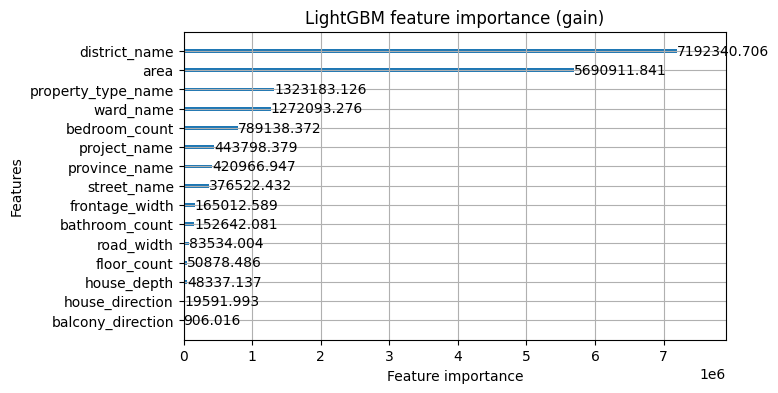

In [9]:
plot_importance(lgbm, importance_type="gain", figsize=(7, 4), title="LightGBM feature importance (gain)")
plt.show()

## 3. CatBoost

CatBoost reads the categorical columns as text and encodes them itself, so it gets the original columns.

In [10]:
del best_forest
gc.collect()

catboost = CatBoostRegressor(iterations=2000, learning_rate=0.1, eval_metric="MAE",
                             max_ctr_complexity=1, border_count=64,
                             random_seed=SEED, verbose=200)
catboost.fit(
    X[is_train], y[is_train],
    cat_features=CATEGORICAL,
    eval_set=(X[is_val], y[is_val]),
    early_stopping_rounds=30,
)

results["CatBoost"] = evaluate(y_test, np.expm1(catboost.predict(X[is_test])))
results["CatBoost"]


0:	learn: 0.7665082	test: 0.7152418	best: 0.7152418 (0)	total: 519ms	remaining: 17m 17s
200:	learn: 0.3192496	test: 0.3034117	best: 0.3034117 (200)	total: 56.5s	remaining: 8m 25s
400:	learn: 0.3065017	test: 0.2916586	best: 0.2916586 (400)	total: 1m 43s	remaining: 6m 52s
600:	learn: 0.2999972	test: 0.2853987	best: 0.2853987 (600)	total: 2m 32s	remaining: 5m 54s
800:	learn: 0.2960802	test: 0.2817779	best: 0.2817779 (800)	total: 3m 28s	remaining: 5m 11s
1000:	learn: 0.2929956	test: 0.2790424	best: 0.2790424 (1000)	total: 4m 25s	remaining: 4m 24s
1200:	learn: 0.2906434	test: 0.2771649	best: 0.2771649 (1200)	total: 5m 21s	remaining: 3m 34s
1400:	learn: 0.2887532	test: 0.2755193	best: 0.2755193 (1400)	total: 6m 19s	remaining: 2m 42s
1600:	learn: 0.2871059	test: 0.2741659	best: 0.2741659 (1600)	total: 7m 20s	remaining: 1m 49s
1800:	learn: 0.2857280	test: 0.2729461	best: 0.2729461 (1800)	total: 8m 13s	remaining: 54.5s
1999:	learn: 0.2844298	test: 0.2719204	best: 0.2719204 (1999)	total: 9m	rema

{'MAE (bn VND)': 5.241554580788432,
 'RMSE (bn VND)': 21.064857891389526,
 'R2': 0.65015845711625,
 'MAPE (%)': 31.664426655103632}

## 4. XGBoost

XGBoost needs the categorical columns as the pandas `category` type (`enable_categorical=True`).
Like LightGBM, training stops when the validation MAE has not improved for 50 rounds.

In [11]:
X_xgb = X.astype({column: "category" for column in CATEGORICAL})

xgb = XGBRegressor(n_estimators=2000, learning_rate=0.05, max_depth=8, tree_method="hist",
                   enable_categorical=True, eval_metric="mae", early_stopping_rounds=50,
                   n_jobs=-1, random_state=SEED)
xgb.fit(X_xgb[is_train], y[is_train], eval_set=[(X_xgb[is_val], y[is_val])], verbose=100)

results["XGBoost"] = evaluate(y_test, np.expm1(xgb.predict(X_xgb[is_test])))
results["XGBoost"]

[0]	validation_0-mae:0.73167
[100]	validation_0-mae:0.25028
[200]	validation_0-mae:0.24486
[300]	validation_0-mae:0.24273
[400]	validation_0-mae:0.24077
[500]	validation_0-mae:0.23877
[600]	validation_0-mae:0.23753
[700]	validation_0-mae:0.23623
[800]	validation_0-mae:0.23504
[900]	validation_0-mae:0.23339
[1000]	validation_0-mae:0.23105
[1100]	validation_0-mae:0.23044
[1200]	validation_0-mae:0.22976
[1300]	validation_0-mae:0.22905
[1400]	validation_0-mae:0.22794
[1500]	validation_0-mae:0.22719
[1600]	validation_0-mae:0.22619
[1700]	validation_0-mae:0.22541
[1800]	validation_0-mae:0.22481
[1900]	validation_0-mae:0.22433
[1999]	validation_0-mae:0.22381


{'MAE (bn VND)': 4.484517333001997,
 'RMSE (bn VND)': 18.40138467191084,
 'R2': 0.7330343895456188,
 'MAPE (%)': 26.418360932060008}

## Results

In [12]:
table = pd.DataFrame(results).T

os.makedirs("../reports/metrics", exist_ok=True)
table.to_csv("../reports/metrics/05_tree_ensembles.csv")

table.style.format("{:,.3f}")

,MAE (bn VND),RMSE (bn VND),R2,MAPE (%)
Random Forest,5.406,22.063,0.616,31.222
LightGBM,4.464,18.189,0.739,26.240
CatBoost,5.242,21.065,0.650,31.664
XGBoost,4.485,18.401,0.733,26.418


## Save predictions

Notebook 10 combines the models, so it needs each model's prediction of `log1p(price)` for every validation and test row.
The index is the row number in `model_input.parquet`, which lets notebook 10 line up the predictions of different notebooks.

In [14]:
keep = is_val | is_test
predictions = pd.DataFrame({
    "split": df.loc[keep, "split"],
    "LightGBM": lgbm.predict(X[keep]),
    "CatBoost": catboost.predict(X[keep]),
    "XGBoost": xgb.predict(X_xgb[keep]),
})

os.makedirs("../reports/predictions", exist_ok=True)
predictions.to_parquet("../reports/predictions/05_tree_ensembles.parquet")
predictions.head()

,split,LightGBM,CatBoost,XGBoost
1677900,val,22.836163,21.655833,22.528944
1677901,val,22.274835,22.251559,22.247770
1677902,val,22.033368,22.476992,21.982643
1677903,val,23.597499,23.518906,23.423641
1677904,val,21.882898,21.970409,21.842789
